# 08 时间序列处理

只要数据和"时间"沾边，就离不开这套动作：

1. 把字符串变成 `datetime64`；
2. 用 `.dt` 取出年、月、星期、小时；
3. 用时间当索引，切片、重采样（按天/小时汇总）；
4. 算移动平均、环比、同比；
5. 从时间派生特征（是否周末、时段），喂给模型或做分组。

本节用一份 6 天的网站访问日志（`site_visits.csv`）走一遍。

> 环境：`llm_sft`，从 `python/pandas` 目录启动。

In [1]:
from pathlib import Path

import matplotlib
import pandas as pd

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_columns", 20)

# 画图时中文正常显示
matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
matplotlib.rcParams["axes.unicode_minus"] = False

DATA = Path("data")
if not DATA.exists():
    DATA = Path("python/pandas/data")

visits = pd.read_csv(DATA / "site_visits.csv")
print("行数:", len(visits), "| ts 的 dtype:", visits["ts"].dtype)
visits.head(3)

行数: 342 | ts 的 dtype: str


,ts,user_id,page,device,duration_s
0,2024-03-04T00:19:00,u062,/blog,web,549
1,2024-03-04T06:59:00,u197,/home,android,341
2,2024-03-04T08:30:00,u119,/docs,ios,82


## 1. 把文本变成时间：`to_datetime`

三个关键参数：

- `format`：已知格式时显式指定，最快也最稳（`%Y-%m-%d %H:%M:%S`）；
- `format="mixed"`：一行一个格式，逐行推断（pandas 2.0+）；
- `errors="coerce"`：转不了的变 `NaT`，而不是抛异常。

In [2]:
print(pd.to_datetime("2024-03-04 08:30:00"))
print(pd.to_datetime("2024/03/04 08:30", format="%Y/%m/%d %H:%M"))
print(pd.to_datetime(["2024-03-04", "20240305", "2024/03/06"], format="mixed"))

# 非法值：errors="coerce" 变 NaT
print(pd.to_datetime(["2024-02-30", "abc"], format="mixed", errors="coerce").tolist())

2024-03-04 08:30:00
2024-03-04 08:30:00
DatetimeIndex(['2024-03-04', '2024-03-05', '2024-03-06'], dtype='datetime64[us]', freq=None)
[NaT, NaT]


In [3]:
# 带时区：先本地化，再转换（不传时区时，时间默认是"无时区"的墙上时间）
ts = pd.Timestamp("2024-03-04 08:00:00")
print("本地化:", ts.tz_localize("Asia/Shanghai"))
print("转 UTC:", ts.tz_localize("Asia/Shanghai").tz_convert("UTC"))

本地化: 2024-03-04 08:00:00+08:00
转 UTC: 2024-03-04 00:00:00+00:00


In [4]:
# 整列转换 + 查看结果
visits["ts"] = pd.to_datetime(visits["ts"])
print(visits["ts"].dtype)
print(visits["ts"].min(), "~", visits["ts"].max())

datetime64[us]
2024-03-04 00:19:00 ~ 2024-03-09 23:38:00


## 2. `.dt` 访问器：从时间派生特征

时间列的 `.dt` 相当于字符串列的 `.str`：**整列批量取分量**。

| 属性 | 含义 | 属性 | 含义 |
| --- | --- | --- | --- |
| `.dt.year` / `.dt.month` / `.dt.day` | 年 / 月 / 日 | `.dt.hour` / `.dt.minute` | 时 / 分 |
| `.dt.dayofweek` | 星期（0=周一） | `.dt.day_name()` | 星期名（英文） |
| `.dt.quarter` | 季度 | `.dt.is_month_end` | 是否月末 |
| `.dt.date` | 只保留日期 | `.dt.floor("h")` | 向下取整到小时 |
| `.dt.strftime("%Y-%m")` | 格式化成字符串 | `.dt.total_seconds()` | 时间差转秒 |

In [5]:
derived = pd.DataFrame({
    "year": visits["ts"].dt.year,
    "month": visits["ts"].dt.month,
    "day": visits["ts"].dt.day,
    "hour": visits["ts"].dt.hour,
    "weekday": visits["ts"].dt.dayofweek,
    "weekday_cn": visits["ts"].dt.dayofweek.map({0: "周一", 1: "周二", 2: "周三", 3: "周四", 4: "周五", 5: "周六", 6: "周日"}),
    "is_weekend": visits["ts"].dt.dayofweek >= 5,
    "month_label": visits["ts"].dt.strftime("%Y-%m"),
})
derived.head(5)

,year,month,day,hour,weekday,weekday_cn,is_weekend,month_label
0,2024,3,4,0,0,周一,False,2024-03
1,2024,3,4,6,0,周一,False,2024-03
2,2024,3,4,8,0,周一,False,2024-03
3,2024,3,4,8,0,周一,False,2024-03
4,2024,3,4,9,0,周一,False,2024-03


Text(0, 0.5, '访问次数')

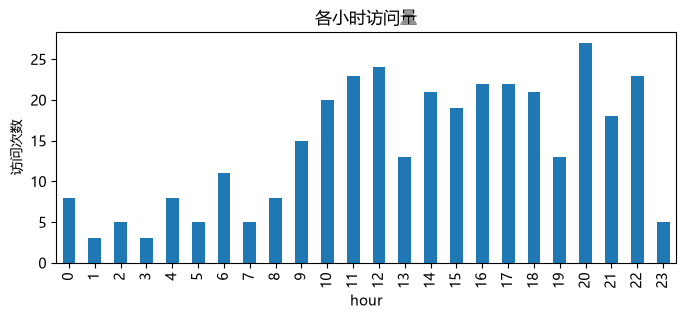

In [6]:
# 按小时看访问分布（figsize 控制图片尺寸，中文标题已在第一个 cell 设置好字体）
ax = (
    visits.assign(hour=visits["ts"].dt.hour)
    .groupby("hour")["user_id"]
    .count()
    .plot(kind="bar", figsize=(8, 3), title="各小时访问量")
)
ax.set_ylabel("访问次数")

## 3. 用时间当索引：切片和重采样都靠它

把 `ts` 设为索引并排序后，可以直接用日期字符串切片，`resample` 也才有意义。

In [7]:
ts_index = visits.set_index("ts").sort_index()
print("索引类型:", type(ts_index.index).__name__)
print("切片 2024-03-05 当天:", len(ts_index.loc["2024-03-05"]))
print("切片 03-05 到 03-06:", len(ts_index.loc["2024-03-05":"2024-03-06"]))
print("只看工作时段 9:00-18:00:", len(ts_index.between_time("09:00", "18:00")))

索引类型: DatetimeIndex
切片 2024-03-05 当天: 54
切片 03-05 到 03-06: 116
只看工作时段 9:00-18:00: 179


## 4. `resample`：时间维度的 groupby

记住一句话：**`resample` 就是"按时间分组"的 `groupby`**，后面接 `agg` / `sum` / `count` 都可以。

| 频率 | 含义 | 备注 |
| --- | --- | --- |
| `"h"` `/ "4h"` | 每小时 / 每 4 小时 | 小写 h |
| `"D"` | 每天 | |
| `"W"` | 每周 | 默认周日记为周末 |
| `"ME"` | 每月末 | pandas 3 里 `"M"` 已废弃，要用 `"ME"` |
| `"QE"` | 每季度末 | 同理，`"Q"` → `"QE"` |

In [8]:
daily = ts_index.resample("D").agg(
    访问量=("user_id", "count"),
    独立用户=("user_id", "nunique"),
    总时长=("duration_s", "sum"),
)
daily["人均时长"] = (daily["总时长"] / daily["访问量"]).round(1)
daily

,访问量,独立用户,总时长,人均时长
ts,,,,
2024-03-04,58,50,14711,253.6
2024-03-05,54,49,16133,298.8
2024-03-06,62,53,18334,295.7
2024-03-07,44,40,14306,325.1
2024-03-08,60,49,18950,315.8
2024-03-09,64,52,20445,319.5


In [9]:
# 每 4 小时聚合（看一天之内的作息）
four_hour = ts_index.resample("4h")["user_id"].count().rename("访问量")
four_hour.head(10)

ts
2024-03-04 00:00:00     1
2024-03-04 04:00:00     1
2024-03-04 08:00:00    12
2024-03-04 12:00:00    11
2024-03-04 16:00:00    14
2024-03-04 20:00:00    19
2024-03-05 00:00:00     3
2024-03-05 04:00:00     2
2024-03-05 08:00:00    13
2024-03-05 12:00:00    11
Freq: 4h, Name: 访问量, dtype: int64

In [10]:
# resample 会补全所有时间格子；asfreq 则是"只换频率，缺的就是 NaN"
print("asfreq 12h（有 NaN）:")
print(daily["访问量"].asfreq("12h").head(6))
print("\nfillna 后:")
print(daily["访问量"].asfreq("12h").ffill().head(6))

asfreq 12h（有 NaN）:
ts
2024-03-04 00:00:00    58.0
2024-03-04 12:00:00     NaN
2024-03-05 00:00:00    54.0
2024-03-05 12:00:00     NaN
2024-03-06 00:00:00    62.0
2024-03-06 12:00:00     NaN
Freq: 12h, Name: 访问量, dtype: float64

fillna 后:
ts
2024-03-04 00:00:00    58.0
2024-03-04 12:00:00    58.0
2024-03-05 00:00:00    54.0
2024-03-05 12:00:00    54.0
2024-03-06 00:00:00    62.0
2024-03-06 12:00:00    62.0
Freq: 12h, Name: 访问量, dtype: float64


## 5. 移动窗口：`rolling` / `expanding` / `ewm`

- `rolling(n)`：最近 n 个点的窗口（移动平均、移动最大）；
- `rolling("3D")`：按**时间长度**的窗口，要求时间是索引；
- `expanding()`：从第一个点到现在（累计均值）；
- `ewm(span=n)`：指数加权，越近的点权重越大。

In [11]:
moves = pd.DataFrame({
    "访问量": daily["访问量"],
    "3日均值": daily["访问量"].rolling(3).mean().round(1),
    "累计均值": daily["访问量"].expanding().mean().round(1),
    "指数平滑": daily["访问量"].ewm(span=3).mean().round(1),
})
moves

,访问量,3日均值,累计均值,指数平滑
ts,,,,
2024-03-04,58,NaN,58.0,58.0
2024-03-05,54,NaN,56.0,55.3
2024-03-06,62,58.0,58.0,59.1
2024-03-07,44,53.3,54.5,51.1
2024-03-08,60,55.3,55.6,55.7
2024-03-09,64,56.0,57.0,59.9


In [12]:
# 按时间长度滚动：最近 2 天
ts_index["user_id"].resample("D").count().rolling("2D").sum().head(6)

ts
2024-03-04     58.0
2024-03-05    112.0
2024-03-06    116.0
2024-03-07    106.0
2024-03-08    104.0
2024-03-09    124.0
Freq: D, Name: user_id, dtype: float64

## 6. 环比与同比：`shift` / `diff` / `pct_change`

- `shift(1)`：整体下移一行（取"上一期"）；
- `diff()`：本期 - 上一期；
- `pct_change()`：环比增长率。

In [13]:
daily["昨日访问量"] = daily["访问量"].shift(1)
daily["环比增量"] = daily["访问量"].diff()
daily["环比增长率"] = (daily["访问量"].pct_change() * 100).round(1)
daily[["访问量", "昨日访问量", "环比增量", "环比增长率"]]

,访问量,昨日访问量,环比增量,环比增长率
ts,,,,
2024-03-04,58,NaN,NaN,NaN
2024-03-05,54,58.0,-4.0,-6.9
2024-03-06,62,54.0,8.0,14.8
2024-03-07,44,62.0,-18.0,-29.0
2024-03-08,60,44.0,16.0,36.4
2024-03-09,64,60.0,4.0,6.7


## 7. 周期、区间与时间差

- `date_range`：生成规则的时间序列（补日期、画图对齐）；
- `to_period("M")`：把时间归到"月"这个周期，适合按月分组；
- 时间相减得到 `timedelta`，用 `.dt.days` / `.dt.total_seconds()` 转成数字。

In [14]:
print(pd.date_range("2024-03-01", "2024-03-08", freq="D").tolist())

print("\n按周期分组:")
visits["ts"].dt.to_period("M").value_counts().sort_index()

print("\n每行距最早访问过了多少小时:")
hours = (visits["ts"] - visits["ts"].min()).dt.total_seconds() / 3600
hours.round(1).head().tolist()

[Timestamp('2024-03-01 00:00:00'), Timestamp('2024-03-02 00:00:00'), Timestamp('2024-03-03 00:00:00'), Timestamp('2024-03-04 00:00:00'), Timestamp('2024-03-05 00:00:00'), Timestamp('2024-03-06 00:00:00'), Timestamp('2024-03-07 00:00:00'), Timestamp('2024-03-08 00:00:00')]

按周期分组:

每行距最早访问过了多少小时:


[0.0, 6.7, 8.2, 7.9, 9.1]

In [15]:
# 计算每个用户的首访、末访、留存时长
user_life = visits.groupby("user_id")["ts"].agg(["min", "max"])
user_life["留存天数"] = (user_life["max"] - user_life["min"]).dt.days
user_life.sort_values("留存天数", ascending=False).head(5)

,min,max,留存天数
user_id,,,
u015,2024-03-04 10:22:00,2024-03-09 12:33:00,5
u036,2024-03-04 20:46:00,2024-03-09 22:55:00,5
u027,2024-03-04 18:18:00,2024-03-09 22:16:00,5
u156,2024-03-04 09:04:00,2024-03-09 15:30:00,5
u064,2024-03-04 10:46:00,2024-03-09 12:34:00,5


## 8. 小练习

1. 找出访问量最高的那个小时（`hour` + `value_counts` 或 resample("h")）；
2. 比较工作日和周末的平均日访问量；
3. 给日访问量加一列"7 日移动平均"，并找出移动平均最高的一天。

In [16]:
peak_hour = ts_index.resample("h")["user_id"].count()
print("访问量最高的小时:", peak_hour.idxmax(), "→", peak_hour.max(), "次访问")

访问量最高的小时: 2024-03-04 22:00:00 → 8 次访问


In [17]:
daily_kind = daily.assign(是否周末=daily.index.dayofweek >= 5)
daily_kind.groupby("是否周末")["访问量"].mean().round(1)

是否周末
False    55.6
True     64.0
Name: 访问量, dtype: float64

In [18]:
daily["7日均值"] = daily["访问量"].rolling(7, min_periods=1).mean().round(1)
daily.sort_values("7日均值", ascending=False).head(3)[["访问量", "7日均值"]]

,访问量,7日均值
ts,,
2024-03-04,58,58.0
2024-03-06,62,58.0
2024-03-09,64,57.0


## 9. 小结

**标准流程**

```python
df["ts"] = pd.to_datetime(df["ts"], errors="coerce")   # 1. 转时间
df = df.set_index("ts").sort_index()                   # 2. 当索引
df.resample("D").agg(...)                              # 3. 按天汇总
df["v"].rolling(7).mean()                              # 4. 移动平均
```

**容易踩的坑**

1. `resample` 的索引必须是 `DatetimeIndex` 且**有序**，否则先 `sort_index()`。
2. pandas 3 里 `"M"` / `"Q"` 频率已废弃，改用 `"ME"` / `"QE"`。
3. `resample` 默认补齐所有时间格子（空桶为 0 或 NaN），会导致"没数据的日子"被算进平均。
4. `pct_change` 第一行永远是 NaN（没有上一期）。
5. 时区：`tz_localize` 给"无时区"的时间加上时区，`tz_convert` 才是转换已有时间的时区。